# H2 (RDP): Theoretical vs. Empirical Bounds

**H2** — Does the empirical number of private branch calls to realise $k$ target hits
remain below the prepaid bound $K_k$, with failure probability at most $\delta$?

Two figures:
1. **Theoretical vs. Empirical Bounds** — $K_k$ (worst-case prepaid) against the simulated distribution of $T_k$ (rounds to $k$-th hit).
2. **Empirical Failure Rate vs. $\delta$** — for each choice of $\delta$, the fraction of runs where $T_k > K_k(\delta)$ for any $k$, compared against the $y = \delta$ guarantee line.


In [1]:
import sys
sys.path.insert(0, '..')

import math
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from simulation.accountants.adaptive_tct import AdaptiveTCTAccountant
from simulation.calibration import q_from_epsilon

plt.rcParams.update({
    'figure.dpi': 150, 'font.size': 10, 'axes.labelsize': 10,
    'axes.titlesize': 11, 'legend.fontsize': 8.5,
    'lines.linewidth': 1.8, 'axes.spines.top': False, 'axes.spines.right': False,
})

TCT_Z_COLOR = '#2166ac'
TCT_S_COLOR = '#1a9641'

EPSILON    = 0.01
DELTA      = 1e-2
ALPHA_RDP  = 75.0
rho        = ALPHA_RDP * EPSILON**2 / 2.0
q          = q_from_epsilon(EPSILON)

N_RUNS     = 10_000
K_MAX      = 50      # verify anytime bound up to 50 hits
SEED       = 42

print(f'ε={EPSILON},  α={ALPHA_RDP:.0f},  ρ={rho:.6f},  δ={DELTA:.0e}')
print(f'q = {q:.6f}  (NotPrior target, Lemma 2.3)')
print(f'N_RUNS = {N_RUNS:,}  ·  K_MAX = {K_MAX}')
print()

acc_z = AdaptiveTCTAccountant(EPSILON, DELTA, alpha_rdp=ALPHA_RDP, schedule='zeta2')
acc_s = AdaptiveTCTAccountant(EPSILON, DELTA, alpha_rdp=ALPHA_RDP, schedule='stitched')

k_vals    = list(range(1, K_MAX + 1))
K_z       = [acc_z.compositions(k) for k in k_vals]
K_s       = [acc_s.compositions(k) for k in k_vals]
delta_k_z = [6.0 / (math.pi**2 * k**2) * DELTA for k in k_vals]
delta_k_s = [6.0 / (math.pi**2 * math.ceil(math.log2(max(k, 2)))**2) * DELTA
             for k in k_vals]

print(f'{"k":>4}  {"K_k Zeta-2":>12}  {"K_k Stitched":>14}  {"δ_k Zeta-2":>12}')
print('-' * 50)
for i, k in enumerate(k_vals[:10]):
    print(f'{k:>4}  {K_z[i]:>12.1f}  {K_s[i]:>14.1f}  {delta_k_z[i]:>12.6f}')


ε=0.01,  α=75,  ρ=0.003750,  δ=1e-02
q = 0.497500  (NotPrior target, Lemma 2.3)
N_RUNS = 10,000  ·  K_MAX = 50

   k    K_k Zeta-2    K_k Stitched    δ_k Zeta-2
--------------------------------------------------
   1          24.4            84.1      0.006079
   2          33.6            86.1      0.001520
   3          40.5           110.4      0.000675
   4          46.3           112.4      0.000380
   5          51.6           127.4      0.000243
   6          56.5           129.4      0.000169
   7          61.1           131.5      0.000124
   8          65.4           133.5      0.000095
   9          69.7           144.7      0.000075
  10          73.7           146.7      0.000061


## Simulation

Each round is an independent Bernoulli($q$) trial — the Laplace threshold mechanism
guarantees each round is a $q$-target (Lemma 2.3). The number of rounds between
consecutive hits is Geom($q$), so cumulative inter-arrivals give the exact joint
distribution of $(T_1, T_2, \ldots, T_K)$ without running the full DP mechanism.


In [2]:
rng = np.random.default_rng(SEED)

# inter_arrivals[run, k-1] ~ Geom(q): rounds between (k-1)-th and k-th hit
# T_matrix[run, k-1] = T_k: total rounds until k-th hit
inter_arrivals = rng.geometric(q, size=(N_RUNS, K_MAX))
T_matrix = np.cumsum(inter_arrivals, axis=1).astype(float)   # (N_RUNS, K_MAX)

print(f'T_matrix shape: {T_matrix.shape}')
print()
print(f'{"k":>4}  {"K_k(Z)":>9}  {"T_k median":>11}  {"T_k 95th":>10}  '
      f'{"T_k 99th":>10}  {"T_k max":>10}  {"T_k>K_k ?":>10}')
print('-' * 72)
for i, k in enumerate(k_vals[:10]):
    med  = np.median(T_matrix[:, i])
    p95  = np.percentile(T_matrix[:, i], 95)
    p99  = np.percentile(T_matrix[:, i], 99)
    mx   = T_matrix[:, i].max()
    any_exceed = np.any(T_matrix[:, i] > K_z[i])
    print(f'{k:>4}  {K_z[i]:>9.1f}  {med:>11.1f}  {p95:>10.1f}  '
          f'{p99:>10.1f}  {mx:>10.1f}  {"YES" if any_exceed else "no":>10}')


T_matrix shape: (10000, 50)

   k     K_k(Z)   T_k median    T_k 95th    T_k 99th     T_k max   T_k>K_k ?
------------------------------------------------------------------------
   1       24.4          1.0         5.0         7.0        14.0          no
   2       33.6          3.0         8.0        11.0        18.0          no
   3       40.5          5.0        11.0        14.0        26.0          no
   4       46.3          8.0        13.0        17.0        27.0          no
   5       51.6          9.0        16.0        20.0        29.0          no
   6       56.5         11.0        18.0        22.0        33.0          no
   7       61.1         13.0        21.0        25.0        35.0          no
   8       65.4         15.0        23.0        28.0        38.0          no
   9       69.7         18.0        26.0        30.0        40.0          no
  10       73.7         19.0        28.0        33.0        43.0          no


## Figure 1 — Theoretical vs. Empirical Bounds

**Left panel:** prepaid bound $K_k$ (lines) above the empirical distribution of
$T_k$ (shaded bands: 50th/75th/95th/99th percentile). The dotted line is the oracle
cost $k/q$ — the minimum possible if you knew $k$ in advance. H2 requires every
shaded region to stay below its bound.

**Right panel:** overhead factor $K_k / (k/q)$ — how much extra you pay for the
anytime guarantee relative to the oracle. Converges toward 1 as $k \to \infty$.


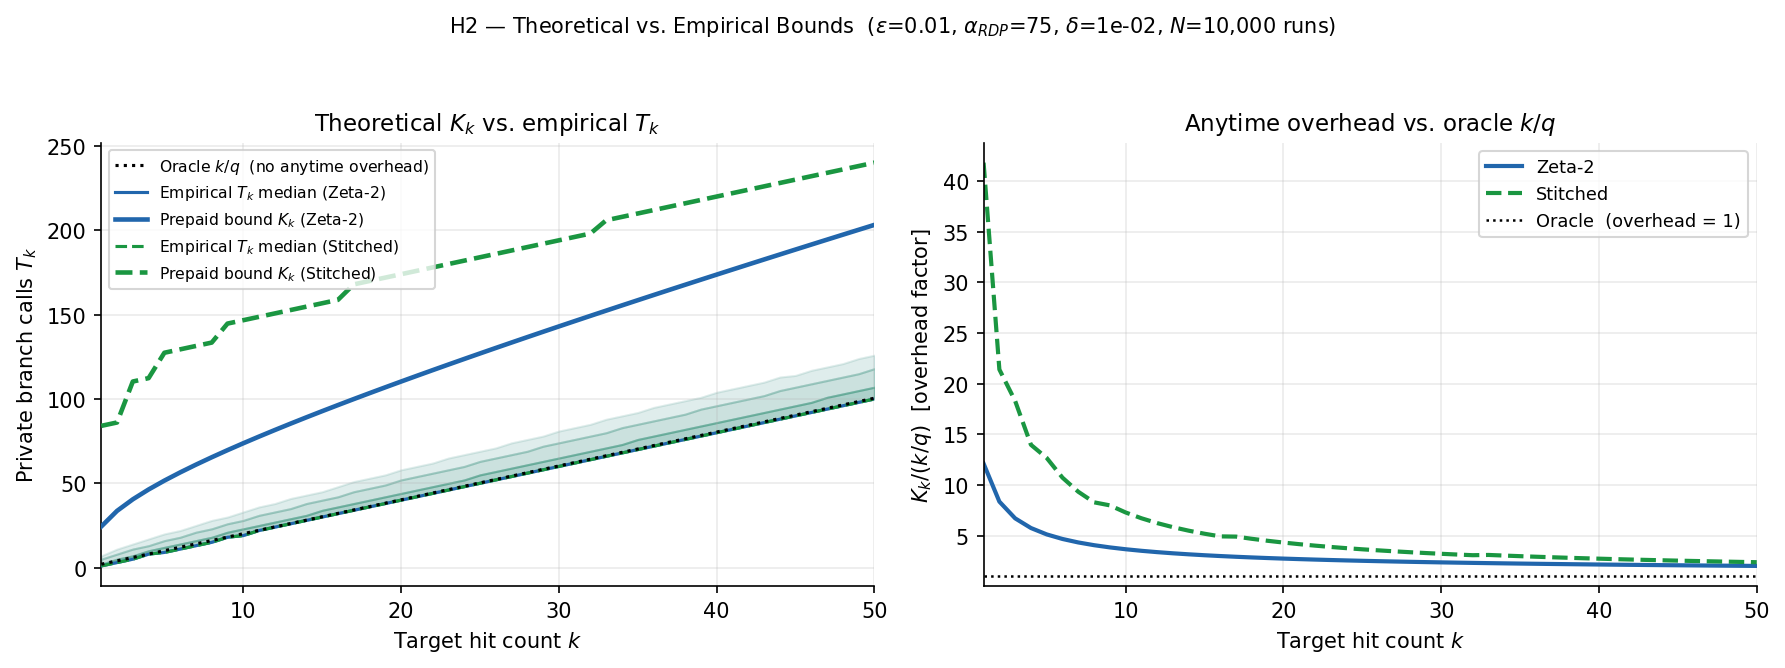

Saved h2_rdp_bounds.png


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# ── Left: T_k distribution vs K_k ────────────────────────────────────────────
ax = axes[0]
oracle = np.array([k / q for k in k_vals])
ax.plot(k_vals, oracle, 'k:', lw=1.5, zorder=5, label='Oracle $k/q$  (no anytime overhead)')

for color, K_sched, lbl, ls in [
    (TCT_Z_COLOR, np.array(K_z), 'Zeta-2',   '-'),
    (TCT_S_COLOR, np.array(K_s), 'Stitched', '--'),
]:
    q50  = np.array([np.percentile(T_matrix[:, i], 50)  for i in range(K_MAX)])
    prev = q50.copy()
    for pct, a in zip([75, 95, 99], [0.20, 0.12, 0.07]):
        qp = np.array([np.percentile(T_matrix[:, i], pct) for i in range(K_MAX)])
        ax.fill_between(k_vals, prev, qp, color=color, alpha=a, zorder=1)
        prev = qp
    ax.plot(k_vals, q50,    color=color, lw=1.5, ls=ls, zorder=3,
            label=f'Empirical $T_k$ median ({lbl})')
    ax.plot(k_vals, K_sched, color=color, lw=2.2, ls=ls, zorder=4,
            label=f'Prepaid bound $K_k$ ({lbl})')

ax.set_xlabel('Target hit count $k$')
ax.set_ylabel('Private branch calls $T_k$')
ax.set_title('Theoretical $K_k$ vs. empirical $T_k$')
ax.set_xlim(1, K_MAX)
ax.legend(loc='upper left', fontsize=7.5)
ax.grid(True, alpha=0.25)

# ── Right: overhead factor K_k / (k/q) ───────────────────────────────────────
ax = axes[1]
overhead_z = [K_z[i] / (k / q) for i, k in enumerate(k_vals)]
overhead_s = [K_s[i] / (k / q) for i, k in enumerate(k_vals)]
ax.plot(k_vals, overhead_z, color=TCT_Z_COLOR, lw=2,       label='Zeta-2')
ax.plot(k_vals, overhead_s, color=TCT_S_COLOR, lw=2, ls='--', label='Stitched')
ax.axhline(1.0, color='k', lw=1.2, ls=':', label='Oracle  (overhead = 1)')
ax.set_xlabel('Target hit count $k$')
ax.set_ylabel('$K_k / (k/q)$  [overhead factor]')
ax.set_title('Anytime overhead vs. oracle $k/q$')
ax.set_xlim(1, K_MAX)
ax.legend(fontsize=8.5)
ax.grid(True, alpha=0.25)

fig.suptitle(
    rf'H2 — Theoretical vs. Empirical Bounds'
    rf'  ($\varepsilon$={EPSILON}, $\alpha_{{RDP}}$={ALPHA_RDP:.0f}, '
    rf'$\delta$={DELTA:.0e}, $N$={N_RUNS:,} runs)',
    fontsize=10,
)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig('../figures/h2_rdp_bounds.png', bbox_inches='tight', dpi=200)
plt.show()
print('Saved h2_rdp_bounds.png')


## Figure 2 — Empirical Failure Rate vs. $\delta$

**X-axis:** target failure budget $\delta$.  
**Y-axis:** failure probability (log scale).

Three things on the same axes:
- **Dashed diagonal** $y = \delta$: the stated guarantee — empirical must stay below this.
- **Smooth curves**: exact theoretical $\sum_k P(T_k > K_k(\delta))$ via `scipy.stats.nbinom` —
  the union bound that is always $\leq \delta$ by construction, visible across the full x-axis range.
- **Scatter points**: empirical failure rate (fraction of {N_RUNS:,} runs where $T_k > K_k(\delta)$
  for any $k$) — only appear where failures are observable above the $1/N$ detection floor.


Computing theoretical union bounds and empirical failure rates ...


Done.
Observable empirical failures  Zeta-2: 31/80  Stitched: 6/80
Max exact bound  Zeta-2: 0.0332  Stitched: 0.0044
Max empirical    Zeta-2: 0.0307  Stitched: 0.0033
All exact bounds ≤ delta? True


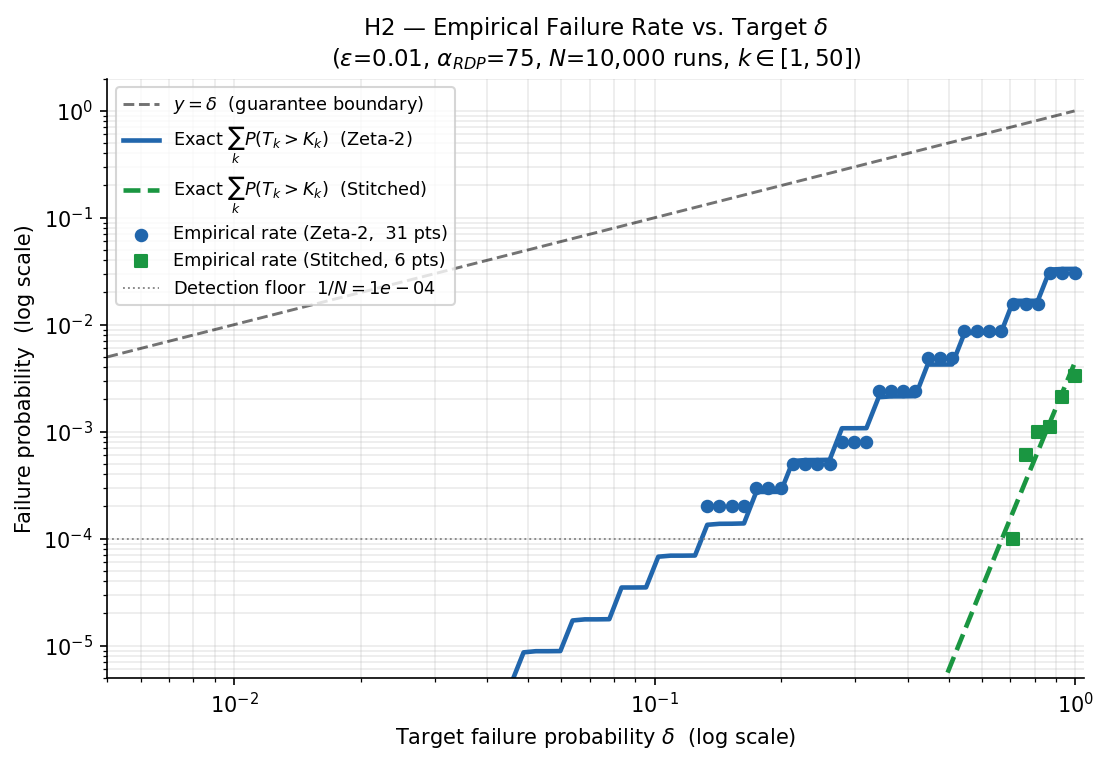

Saved h2_rdp_failure_rate.png


In [4]:
from scipy.stats import nbinom

print('Computing theoretical union bounds and empirical failure rates ...')

delta_sweep    = np.logspace(np.log10(0.005), np.log10(0.995), 80)
exact_bound_z  = np.zeros(len(delta_sweep))
exact_bound_s  = np.zeros(len(delta_sweep))
fail_rates_z   = np.zeros(len(delta_sweep))
fail_rates_s   = np.zeros(len(delta_sweep))

for idx, dv in enumerate(delta_sweep):
    az  = AdaptiveTCTAccountant(EPSILON, dv, alpha_rdp=ALPHA_RDP, schedule='zeta2')
    as_ = AdaptiveTCTAccountant(EPSILON, dv, alpha_rdp=ALPHA_RDP, schedule='stitched')
    Kzd = np.array([az.compositions(k)  for k in k_vals])
    Ksd = np.array([as_.compositions(k) for k in k_vals])

    # Exact P(T_k > K_k):  T_k = k + F,  F ~ NegBinom(k, q)
    # P(T_k > K_k) = P(F > floor(K_k) - k) = nbinom.sf(floor(K_k) - k, k, q)
    bz = sum(float(nbinom.sf(int(Kzd[i]) - k, k, q)) for i, k in enumerate(k_vals))
    bs = sum(float(nbinom.sf(int(Ksd[i]) - k, k, q)) for i, k in enumerate(k_vals))
    exact_bound_z[idx] = bz
    exact_bound_s[idx] = bs

    # Empirical: any T_k > K_k across k=1..K_MAX in the same run
    fail_rates_z[idx] = float(np.mean(np.any(T_matrix > Kzd[np.newaxis, :], axis=1)))
    fail_rates_s[idx] = float(np.mean(np.any(T_matrix > Ksd[np.newaxis, :], axis=1)))

print('Done.')
MIN_OBS = 1.0 / N_RUNS
nz_z = np.sum(fail_rates_z > 0)
nz_s = np.sum(fail_rates_s > 0)
print(f'Observable empirical failures  Zeta-2: {nz_z}/{len(delta_sweep)}  '
      f'Stitched: {nz_s}/{len(delta_sweep)}')
print(f'Max exact bound  Zeta-2: {exact_bound_z.max():.4f}  '
      f'Stitched: {exact_bound_s.max():.4f}')
print(f'Max empirical    Zeta-2: {fail_rates_z.max():.4f}  '
      f'Stitched: {fail_rates_s.max():.4f}')
print(f'All exact bounds ≤ delta? '
      f'{all(exact_bound_z[i] <= delta_sweep[i] + 1e-12 for i in range(len(delta_sweep)))}')

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7.5, 5.2))

# y = delta reference (guarantee boundary)
ref = np.logspace(np.log10(0.005), np.log10(0.995), 300)
ax.plot(ref, ref, 'k--', lw=1.4, alpha=0.55,
        label=r'$y = \delta$  (guarantee boundary)')

# Exact theoretical union bounds — smooth, non-zero across full range
ax.plot(delta_sweep, exact_bound_z, color=TCT_Z_COLOR, lw=2.2,
        label=r'Exact $\sum_k P(T_k > K_k)$  (Zeta-2)')
ax.plot(delta_sweep, exact_bound_s, color=TCT_S_COLOR, lw=2.2, ls='--',
        label=r'Exact $\sum_k P(T_k > K_k)$  (Stitched)')

# Empirical scatter — only where observable above detection floor
mask_z = fail_rates_z > 0
mask_s = fail_rates_s > 0
if mask_z.any():
    ax.scatter(delta_sweep[mask_z], fail_rates_z[mask_z],
               color=TCT_Z_COLOR, s=30, zorder=5,
               label=f'Empirical rate (Zeta-2,  {mask_z.sum()} pts)')
if mask_s.any():
    ax.scatter(delta_sweep[mask_s], fail_rates_s[mask_s],
               color=TCT_S_COLOR, s=30, marker='s', zorder=5,
               label=f'Empirical rate (Stitched, {mask_s.sum()} pts)')

# Detection floor
ax.axhline(MIN_OBS, color='#888888', lw=0.9, ls=':',
           label=f'Detection floor  $1/N = {MIN_OBS:.0e}$')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(0.005, 1.05)
# y-axis: from a bit below MIN_OBS up to ~1; clip extreme-low Stitched values
ax.set_ylim(MIN_OBS / 20, 2.0)
ax.set_xlabel(r'Target failure probability $\delta$  (log scale)')
ax.set_ylabel('Failure probability  (log scale)')
ax.set_title(
    rf'H2 — Empirical Failure Rate vs. Target $\delta$' + '\n'
    + rf'($\varepsilon$={EPSILON}, $\alpha_{{RDP}}$={ALPHA_RDP:.0f}, '
    + rf'$N$={N_RUNS:,} runs, $k \in [1, {K_MAX}]$)'
)
ax.legend(fontsize=8.5, loc='upper left')
ax.grid(True, alpha=0.25, which='both')

plt.tight_layout()
plt.savefig('../figures/h2_rdp_failure_rate.png', bbox_inches='tight', dpi=200)
plt.show()
print('Saved h2_rdp_failure_rate.png')


## Summary

In [5]:
print('=== H2 Summary ===')
print(f'ε={EPSILON}, α={ALPHA_RDP:.0f}, ρ={rho:.6f}, δ={DELTA:.0e}, q={q:.6f}')
print(f'N_RUNS={N_RUNS:,},  K_MAX={K_MAX}')
print()
print(f'{"k":>4}  {"K_k(Z)":>9}  {"K_k(S)":>9}  '
      f'{"T_k 99th":>10}  {"T_k max":>10}  {"99th<K_k?":>10}')
print('-' * 60)
for i, k in enumerate(k_vals):
    p99 = np.percentile(T_matrix[:, i], 99)
    mx  = T_matrix[:, i].max()
    ok  = '✓' if (p99 < K_z[i] and p99 < K_s[i]) else '✗'
    print(f'{k:>4}  {K_z[i]:>9.1f}  {K_s[i]:>9.1f}  '
          f'{p99:>10.1f}  {mx:>10.1f}  {ok:>10}')

print()
print(f'Max empirical failure rate  Zeta-2:   {fail_rates_z.max():.4f}')
print(f'Max empirical failure rate  Stitched: {fail_rates_s.max():.4f}')
print('All empirical rates ≤ δ? ', all(fail_rates_z <= delta_sweep + 1e-9) and
      all(fail_rates_s <= delta_sweep + 1e-9))


=== H2 Summary ===
ε=0.01, α=75, ρ=0.003750, δ=1e-02, q=0.497500
N_RUNS=10,000,  K_MAX=50

   k     K_k(Z)     K_k(S)    T_k 99th     T_k max   99th<K_k?
------------------------------------------------------------
   1       24.4       84.1         7.0        14.0           ✓
   2       33.6       86.1        11.0        18.0           ✓
   3       40.5      110.4        14.0        26.0           ✓
   4       46.3      112.4        17.0        27.0           ✓
   5       51.6      127.4        20.0        29.0           ✓
   6       56.5      129.4        22.0        33.0           ✓
   7       61.1      131.5        25.0        35.0           ✓
   8       65.4      133.5        28.0        38.0           ✓
   9       69.7      144.7        30.0        40.0           ✓
  10       73.7      146.7        33.0        43.0           ✓
  11       77.7      148.8        36.0        46.0           ✓
  12       81.6      150.8        38.0        47.0           ✓
  13       85.4      152.8   